### import's

In [2]:
import tensorflow as tf
from numpy import loadtxt
from keras.models import Sequential
from keras.layers import Dense, Input, Dropout, BatchNormalization, Activation
from tensorflow.keras.callbacks import EarlyStopping, LearningRateScheduler
from numpy import exp
from tensorflow.keras import Model

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV
from keras.wrappers.scikit_learn import KerasRegressor,KerasClassifier


In [25]:
from keras.datasets import boston_housing

(train_data, train_targets), (test_data, test_targets) = boston_housing.load_data()

In [29]:
train_data.shape

(404, 13)

### def model

In [3]:
def exp_decay(self, epoch):
    initial_lrate = 0.001
    k = 0.1
    lrate = initial_lrate * exp(-k*epoch)
    return lrate


def create_model_neurons(optimizer='Adam',layers=2,dropout = 0.2, neurons=1,epochs=100):
    # create model
    model = Sequential()
    model.add(Dense(neurons, input_dim=8, kernel_initializer='uniform'))
    model.add(BatchNormalization())
    model.add(Activation('relu'))
    model.add(Dropout(dropout))
    for layer in range(layers):
        model.add(Dense(neurons, kernel_initializer='uniform'))
        model.add(BatchNormalization())
        model.add(Activation('relu'))
        model.add(Dropout(dropout))
    model.add(Dense(1, kernel_initializer='uniform', activation='sigmoid'))
    # Compile model
    model.compile(loss='binary_crossentropy', optimizer=optimizer, metrics=['accuracy'])
    return model

In [4]:
# load the dataset
dataset = loadtxt('pima-indians-diabetes.csv', delimiter=',')
# split into input (X) and output (y) variables
X = dataset[:,0:8]
y = dataset[:,8]


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

## Get best model

In [18]:
# create model

model = KerasClassifier(build_fn=create_model_neurons, epochs=100, batch_size=10, verbose=1)

lr_schedule_1 = tf.keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate=0.1,
    decay_steps=100000,
    decay_rate=0.01)
lr_schedule_2 = tf.keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate=0.5,
    decay_steps=100000,
    decay_rate=0.1)
lr_schedule_3 = tf.keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate=0.05,
    decay_steps=100000,
    decay_rate=0.01)

#define the grid search parameters
optimizer = [tf.keras.optimizers.Adam(learning_rate=lr_schedule_1),
             tf.keras.optimizers.Adam(learning_rate=lr_schedule_2),
             tf.keras.optimizers.Adam(learning_rate=lr_schedule_3),]

epochs=[50,]
neurons = [ 5, 15]
layers =[0,2]
dropout=[.15, .25]
param_grid = dict(epochs=epochs,layers=layers,dropout=dropout,optimizer=optimizer,neurons=neurons)

callabacks_list = [EarlyStopping(patience=50,monitor='loss')]
# define the grid search parameters

grid = GridSearchCV(estimator=model, param_grid=param_grid, cv=3,verbose=1)
grid_result = grid.fit(X_train, y_train,callbacks=callabacks_list)
# summarize results
print("Best: %f using %s" % (grid_result.best_score_, grid_result.best_params_))
means = grid_result.cv_results_['mean_test_score']
stds = grid_result.cv_results_['std_test_score']
params = grid_result.cv_results_['params']
for mean, stdev, param in zip(means, stds, params):
    print("%f (%f) with: %r" % (mean, stdev, param))

Fitting 3 folds for each of 24 candidates, totalling 72 fits
Epoch 1/50


C:\Users\diego\AppData\Local\Temp/ipykernel_278796/26276001.py:3: DeprecationWarning: KerasClassifier is deprecated, use Sci-Keras (https://github.com/adriangb/scikeras) instead. See https://www.adriangb.com/scikeras/stable/migration.html for help migrating.
  model = KerasClassifier(build_fn=create_model_neurons, epochs=100, batch_size=10, verbose=1)


35/35 [==============================] - 1s 2ms/step - loss: 0.5803 - accuracy: 0.7076
Epoch 2/50
35/35 [==============================] - 0s 1ms/step - loss: 0.5864 - accuracy: 0.6579
Epoch 3/50
35/35 [==============================] - 0s 3ms/step - loss: 0.5510 - accuracy: 0.6988
Epoch 4/50
35/35 [==============================] - 0s 3ms/step - loss: 0.5475 - accuracy: 0.6871
Epoch 5/50
35/35 [==============================] - 0s 2ms/step - loss: 0.5668 - accuracy: 0.6754
Epoch 6/50
35/35 [==============================] - 0s 2ms/step - loss: 0.5446 - accuracy: 0.6813
Epoch 7/50
35/35 [==============================] - 0s 2ms/step - loss: 0.5302 - accuracy: 0.7164
Epoch 8/50
35/35 [==============================] - 0s 2ms/step - loss: 0.5157 - accuracy: 0.7105
Epoch 9/50
35/35 [==============================] - 0s 2ms/step - loss: 0.5337 - accuracy: 0.7105
Epoch 10/50
35/35 [==============================] - 0s 2ms/step - loss: 0.5279 - accuracy: 0.6930
Epoch 11/50
35/35 [===========

35/35 [==============================] - 0s 1ms/step - loss: 0.5236 - accuracy: 0.7580
Epoch 34/50
35/35 [==============================] - 0s 2ms/step - loss: 0.5129 - accuracy: 0.7464
Epoch 35/50
35/35 [==============================] - 0s 2ms/step - loss: 0.5224 - accuracy: 0.7405
Epoch 36/50
35/35 [==============================] - 0s 2ms/step - loss: 0.5730 - accuracy: 0.6968
Epoch 37/50
35/35 [==============================] - 0s 2ms/step - loss: 0.5673 - accuracy: 0.6968
Epoch 38/50
35/35 [==============================] - 0s 2ms/step - loss: 0.5897 - accuracy: 0.6793
Epoch 39/50
35/35 [==============================] - 0s 1ms/step - loss: 0.5269 - accuracy: 0.7405
Epoch 40/50
35/35 [==============================] - 0s 1ms/step - loss: 0.5431 - accuracy: 0.7085
Epoch 41/50
35/35 [==============================] - 0s 2ms/step - loss: 0.5244 - accuracy: 0.7376
Epoch 42/50
35/35 [==============================] - 0s 2ms/step - loss: 0.4995 - accuracy: 0.7551
Epoch 43/50
35/35 [===

35/35 [==============================] - 0s 1ms/step - loss: 0.6583 - accuracy: 0.6462
Epoch 15/50
35/35 [==============================] - 0s 2ms/step - loss: 0.6520 - accuracy: 0.6462
Epoch 16/50
35/35 [==============================] - 0s 2ms/step - loss: 0.6679 - accuracy: 0.6462
Epoch 17/50
35/35 [==============================] - 0s 2ms/step - loss: 0.6822 - accuracy: 0.6462
Epoch 18/50
35/35 [==============================] - 0s 2ms/step - loss: 0.6747 - accuracy: 0.5936
Epoch 19/50
35/35 [==============================] - 0s 2ms/step - loss: 0.6887 - accuracy: 0.6111
Epoch 20/50
35/35 [==============================] - 0s 2ms/step - loss: 0.6530 - accuracy: 0.6462
Epoch 21/50
35/35 [==============================] - 0s 2ms/step - loss: 0.6659 - accuracy: 0.6462
Epoch 22/50
35/35 [==============================] - 0s 2ms/step - loss: 0.6580 - accuracy: 0.6462
Epoch 23/50
35/35 [==============================] - 0s 1ms/step - loss: 0.6715 - accuracy: 0.6462
Epoch 24/50
35/35 [===

35/35 [==============================] - 0s 2ms/step - loss: 0.6760 - accuracy: 0.6356
Epoch 47/50
35/35 [==============================] - 0s 2ms/step - loss: 0.6749 - accuracy: 0.6472
Epoch 48/50
35/35 [==============================] - 0s 2ms/step - loss: 0.6632 - accuracy: 0.6472
Epoch 49/50
35/35 [==============================] - 0s 2ms/step - loss: 0.6646 - accuracy: 0.6472
Epoch 50/50
18/18 [==============================] - 0s 2ms/step - loss: 0.6542 - accuracy: 0.6433
Epoch 1/50
35/35 [==============================] - 1s 1ms/step - loss: 0.6747 - accuracy: 0.6501
Epoch 2/50
35/35 [==============================] - 0s 1ms/step - loss: 0.6643 - accuracy: 0.6443
Epoch 3/50
35/35 [==============================] - 0s 1ms/step - loss: 0.6605 - accuracy: 0.6443
Epoch 4/50
35/35 [==============================] - 0s 2ms/step - loss: 0.6642 - accuracy: 0.6443
Epoch 5/50
35/35 [==============================] - 0s 2ms/step - loss: 0.6762 - accuracy: 0.5860
Epoch 6/50
35/35 [=========

... (37 outputs left out)

35/35 [==============================] - 0s 2ms/step - loss: 0.6679 - accuracy: 0.6462
Epoch 39/50
35/35 [==============================] - 0s 2ms/step - loss: 0.6545 - accuracy: 0.6462
Epoch 40/50
35/35 [==============================] - 0s 2ms/step - loss: 0.6642 - accuracy: 0.6170
Epoch 41/50
35/35 [==============================] - 0s 2ms/step - loss: 0.6728 - accuracy: 0.6462
Epoch 42/50
35/35 [==============================] - 0s 2ms/step - loss: 0.6624 - accuracy: 0.6462
Epoch 43/50
35/35 [==============================] - 0s 2ms/step - loss: 0.7151 - accuracy: 0.5175
Epoch 44/50
35/35 [==============================] - 0s 2ms/step - loss: 0.6926 - accuracy: 0.6053
Epoch 45/50
35/35 [==============================] - 0s 2ms/step - loss: 0.6583 - accuracy: 0.6462
Epoch 46/50
35/35 [==============================] - 0s 3ms/step - loss: 0.6697 - accuracy: 0.6462
Epoch 47/50
35/35 [==============================] - 0s 2ms/step - loss: 0.7033 - accuracy: 0.5760
Epoch 48/50
35/35 [===

35/35 [==============================] - 0s 2ms/step - loss: 0.6595 - accuracy: 0.6443
Epoch 20/50
35/35 [==============================] - 0s 2ms/step - loss: 0.6574 - accuracy: 0.6443
Epoch 21/50
35/35 [==============================] - 0s 2ms/step - loss: 0.6756 - accuracy: 0.6443
Epoch 22/50
35/35 [==============================] - 0s 3ms/step - loss: 0.6789 - accuracy: 0.6239
Epoch 23/50
35/35 [==============================] - 0s 3ms/step - loss: 0.6622 - accuracy: 0.6385
Epoch 24/50
35/35 [==============================] - 0s 3ms/step - loss: 0.6602 - accuracy: 0.6443
Epoch 25/50
35/35 [==============================] - 0s 3ms/step - loss: 0.6797 - accuracy: 0.6093
Epoch 26/50
35/35 [==============================] - 0s 2ms/step - loss: 0.6738 - accuracy: 0.6210
Epoch 27/50
35/35 [==============================] - 0s 2ms/step - loss: 0.6579 - accuracy: 0.6093
Epoch 28/50
35/35 [==============================] - 0s 3ms/step - loss: 0.6883 - accuracy: 0.6443
Epoch 29/50
35/35 [===

18/18 [==============================] - 0s 2ms/step - loss: 0.5137 - accuracy: 0.7442
Epoch 1/50
35/35 [==============================] - 1s 2ms/step - loss: 0.6598 - accuracy: 0.6210
Epoch 2/50
35/35 [==============================] - 0s 2ms/step - loss: 0.5701 - accuracy: 0.6910
Epoch 3/50
35/35 [==============================] - 0s 2ms/step - loss: 0.5836 - accuracy: 0.6706
Epoch 4/50
35/35 [==============================] - 0s 3ms/step - loss: 0.5688 - accuracy: 0.7289
Epoch 5/50
35/35 [==============================] - 0s 2ms/step - loss: 0.5513 - accuracy: 0.7259
Epoch 6/50
35/35 [==============================] - 0s 2ms/step - loss: 0.5849 - accuracy: 0.6851
Epoch 7/50
35/35 [==============================] - 0s 3ms/step - loss: 0.5517 - accuracy: 0.7085
Epoch 8/50
35/35 [==============================] - 0s 2ms/step - loss: 0.6016 - accuracy: 0.7347
Epoch 9/50
35/35 [==============================] - 0s 2ms/step - loss: 0.5699 - accuracy: 0.7201
Epoch 10/50
35/35 [============

35/35 [==============================] - 0s 3ms/step - loss: 0.5428 - accuracy: 0.7230
Epoch 33/50
35/35 [==============================] - 0s 3ms/step - loss: 0.5279 - accuracy: 0.7405
Epoch 34/50
35/35 [==============================] - 0s 2ms/step - loss: 0.5063 - accuracy: 0.7609
Epoch 35/50
35/35 [==============================] - 0s 2ms/step - loss: 0.5424 - accuracy: 0.7259
Epoch 36/50
35/35 [==============================] - 0s 3ms/step - loss: 0.5108 - accuracy: 0.7434
Epoch 37/50
35/35 [==============================] - 0s 3ms/step - loss: 0.5280 - accuracy: 0.7464
Epoch 38/50
35/35 [==============================] - 0s 3ms/step - loss: 0.5032 - accuracy: 0.7609
Epoch 39/50
35/35 [==============================] - 0s 2ms/step - loss: 0.5278 - accuracy: 0.7638
Epoch 40/50
35/35 [==============================] - 0s 2ms/step - loss: 0.5288 - accuracy: 0.7085
Epoch 41/50
35/35 [==============================] - 0s 3ms/step - loss: 0.5314 - accuracy: 0.7026
Epoch 42/50
35/35 [===

In [24]:
grid_result.best_score_

0.7801011204719543

In [19]:
accuracy_score(y_test,grid_result.best_estimator_.predict(X_test))

0.7362204724409449

# PLot Model

In [20]:
grid_result.best_params_

{'dropout': 0.25,
 'epochs': 50,
 'layers': 0,
 'neurons': 5,
 'optimizer': <keras.optimizer_v2.adam.Adam at 0x165824fb580>}

In [21]:
grid_result.best_estimator_.model.summary()

Model: "sequential_507"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_1954 (Dense)          (None, 5)                 45        
                                                                 
 batch_normalization_1447 (B  (None, 5)                20        
 atchNormalization)                                              
                                                                 
 activation_1447 (Activation  (None, 5)                0         
 )                                                               
                                                                 
 dropout_1447 (Dropout)      (None, 5)                 0         
                                                                 
 dense_1955 (Dense)          (None, 1)                 6         
                                                                 
Total params: 71
Trainable params: 61
Non-trainable 

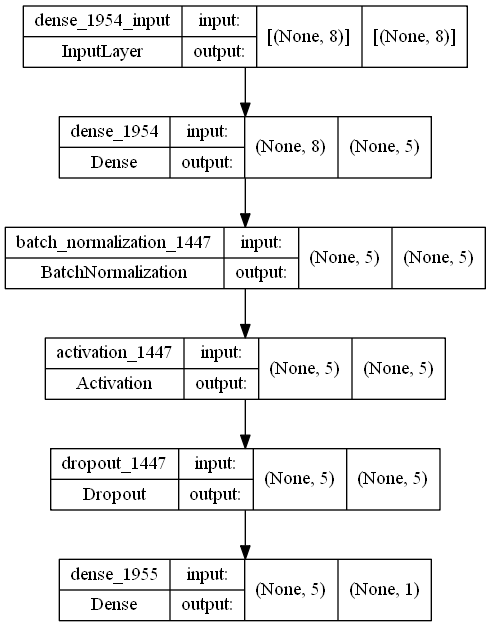

In [22]:
import keras
import pydotplus
from keras.utils.vis_utils import plot_model
keras.utils.vis_utils.pydot = pydotplus
plot_model(grid_result.best_estimator_.model, to_file='model.png', show_shapes=True)

## RandomForestRegressor

In [8]:
from sklearn.ensemble import RandomForestClassifier

In [7]:
param_grid = {
    'bootstrap': [True],
    'max_depth': [50,80,100,],
    'max_features': [ 3,5,7],
    'min_samples_leaf': [3,5,7],
    'min_samples_split': [8,  12],
    'n_estimators': [100, 200,300]
}
# 

In [9]:
# Create a based model
rf = RandomForestClassifier()

grid_search = GridSearchCV(estimator = rf, param_grid = param_grid, 
                          cv = 3, n_jobs = -1, verbose = 2)
grid_search.fit(X_train, y_train)
accuracy_score(y_test,grid_search.predict(X_test))

Fitting 3 folds for each of 162 candidates, totalling 486 fits


0.7677165354330708

In [23]:
grid_search.best_score_

0.7820730767487193

In [10]:
accuracy_score(y_test,grid_search.predict(X_test))

0.7677165354330708